# 01 — EDA and ML Problem Discovery

[Previous](./00_Learning_Roadmap.ipynb) | [Repository guide](../README.md) | [Next](./02_Baselines_and_Validation.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** understand the data, identify the ML problems, and decide what later notebooks must test. No model is trained here.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


## Rules

- Use `train.csv` for exploration.
- Use `test.csv` only to compare feature distributions.
- Do not choose a treatment before measuring the problem.

In [1]:
# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# Optional display settings: readable tables and chart grids.
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)

print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")
display(train.head(3))

Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)


,id,kicker_id,keeper_id,match_id,jersey_color,referee_strictness,stadium_capacity,temperature,weather_humidity,match_type,minute_taken,home_or_away,current_score_diff,pitch_condition,crowd_behind_goal,player_last5_scored_percent,goalkeeper_last5_saved_percent,strong_foot_usage,weak_foot_usage,is_scored
0,0,K438D6085,GKDD557888,M3C40BB2A,NaN,0.6600,79645.0000,23.0000,95.0000,Friendly,65.0000,Home,3,Good,Away,0,60,0.7700,0.3170,0
1,1,K3E7E4B7B,GKE0FB527D,M70B9BC44,Purple,0.3400,79197.0000,27.0000,99.0000,League,1.0000,Home,-2,Fair,Home,20,80,0.7100,0.5380,0
2,2,KED488FF2,GK0AFCB052,MABAFDA12,Blue,0.0500,94819.0000,21.0000,78.0000,League,89.0000,Neutral,0,Good,Home,40,0,0.4670,0.2540,1


## 1. Dataset structure

- **dtype:** the kind of value stored, such as number or text. It tells us which preprocessing methods are possible.
- **unique:** the number of different values. A nearly unique column may be an identifier rather than a reusable pattern.
- **missing %:** the share of rows without a recorded value. This determines whether we impute, drop, or use a missing indicator.
- **duplicate:** an exactly repeated row. Duplicates can over-represent an event and can enter both sides of a random split.
- **role:** our current classification: identifier, category, number, or target.

This audit does not delete anything. It turns each finding into a later experiment.


In [4]:
# Assign a clear role to each column before making the summary table.
column_roles = []
for column in train.columns:
    if column == TARGET:
        role = "target"
    elif column in ID_COLUMNS:
        role = "identifier"
    elif pd.api.types.is_object_dtype(train[column]) or pd.api.types.is_string_dtype(train[column]):
        role = "categorical"
    else:
        role = "numerical"
    column_roles.append(role)

column_audit = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "unique": train.nunique(dropna=False),
    "missing_%": train.isna().mean().mul(100),
    "role": column_roles,
})
display(column_audit)
print(f"Duplicate train rows: {train.duplicated().sum()}")
print(f"Duplicate train IDs: {train['id'].duplicated().sum()}")

,dtype,unique,missing_%,role
id,int64,20000,0.0000,identifier
kicker_id,object,20000,0.0000,identifier
keeper_id,object,20000,0.0000,identifier
match_id,object,20000,0.0000,identifier
jersey_color,object,9,3.1950,categorical
referee_strictness,float64,102,2.9050,numerical
stadium_capacity,float64,17566,2.7350,numerical
temperature,float64,51,2.9050,numerical
weather_humidity,float64,101,3.1100,numerical
match_type,object,5,0.0000,categorical


Duplicate train rows: 0
Duplicate train IDs: 0


**Dataset example and next action**

- If duplicate rows are `0`, there is nothing to remove. If duplicates existed, we would inspect whether they are real repeated events before dropping them.
- `id`, `kicker_id`, `keeper_id`, and `match_id` are nearly unique. They cannot teach the baseline about repeated players or matches, so Notebook 02 excludes them.
- Missing values are measured here and handled in Notebook 03; categories are encoded in Notebook 04.


## 2. Target balance

A **class** is one target outcome: not scored (`0`) or scored (`1`). **Class imbalance** means one outcome appears more often.

The 55/45 split is mild. EDA only records that fact: Notebook 02 uses stratified validation and Notebook 09 tests class weights, oversampling, undersampling, and SMOTE. We do not balance automatically.


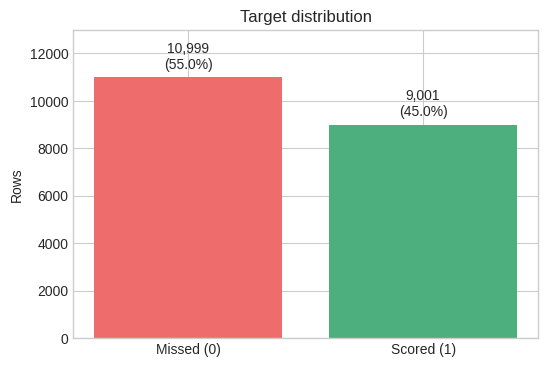

Largest class: 55.0% → mild imbalance


In [5]:
target_counts = train[TARGET].value_counts().sort_index()
target_pct = target_counts.div(len(train)).mul(100)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Missed (0)", "Scored (1)"], target_counts, color=["#ef6c6c", "#4caf7d"])
ax.bar_label(bars, labels=[f"{n:,}\n({p:.1f}%)" for n, p in zip(target_counts, target_pct)], padding=4)
ax.set(title="Target distribution", ylabel="Rows", ylim=(0, target_counts.max() * 1.18))
plt.show()

largest_class = target_pct.max()
balance_label = "mild imbalance" if largest_class < 60 else "meaningful imbalance"
print(f"Largest class: {largest_class:.1f}% → {balance_label}")

## 3. Missing values

A **missing value** means no value was recorded for a row and feature. `isna().sum()` counts these values. Notebook 03 compares filling them (**imputation**), adding a missing `0/1` flag, and explains when `dropna()` is appropriate.

**Next action:** keep the rows for now because every affected column has low missingness; compare treatments with validation.


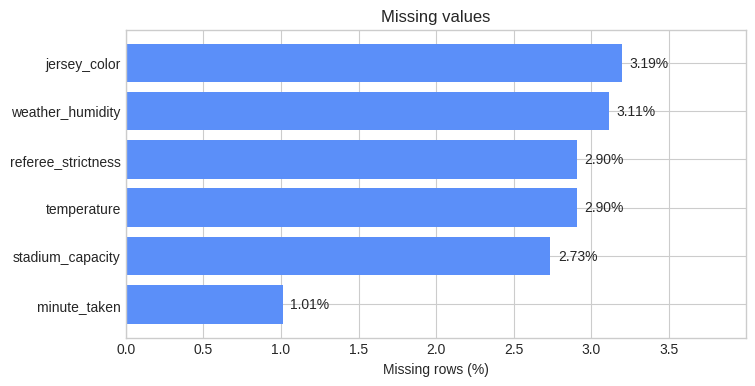

,missing_rows,missing_%
minute_taken,202,1.0100
stadium_capacity,547,2.7350
temperature,581,2.9050
referee_strictness,581,2.9050
weather_humidity,622,3.1100
jersey_color,639,3.1950


In [6]:
# Count missing values as a percentage, then keep affected columns.
missing_percent = train.isna().mean() * 100
missing = missing_percent[missing_percent > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(missing.index, missing.values, color="#5b8ff9")
for i, value in enumerate(missing.values):
    ax.text(value + 0.05, i, f"{value:.2f}%", va="center")
ax.set(title="Missing values", xlabel="Missing rows (%)", xlim=(0, missing.max() * 1.25))
plt.show()
display(pd.DataFrame({"missing_rows": train[missing.index].isna().sum(), "missing_%": missing}))

## 4. Categorical features

- A **categorical feature** contains labels such as `Home`, `Away`, or `Neutral`.
- **Cardinality** is the number of different labels.
- **Frequency** is how often a label appears. It reveals rare/unreliable groups, supports frequency encoding, and helps compare train with test.
- **Scoring rate** is the share of scored penalties inside a label. It can suggest useful categories or interactions, and it is the idea behind target encoding.

Frequency does not use the target; scoring rate does. Neither plot proves that a feature should be kept or removed. A large scoring-rate difference creates a hypothesis to validate; a tiny difference creates an ablation candidate for Notebook 06. Notebook 04 compares safe encodings.


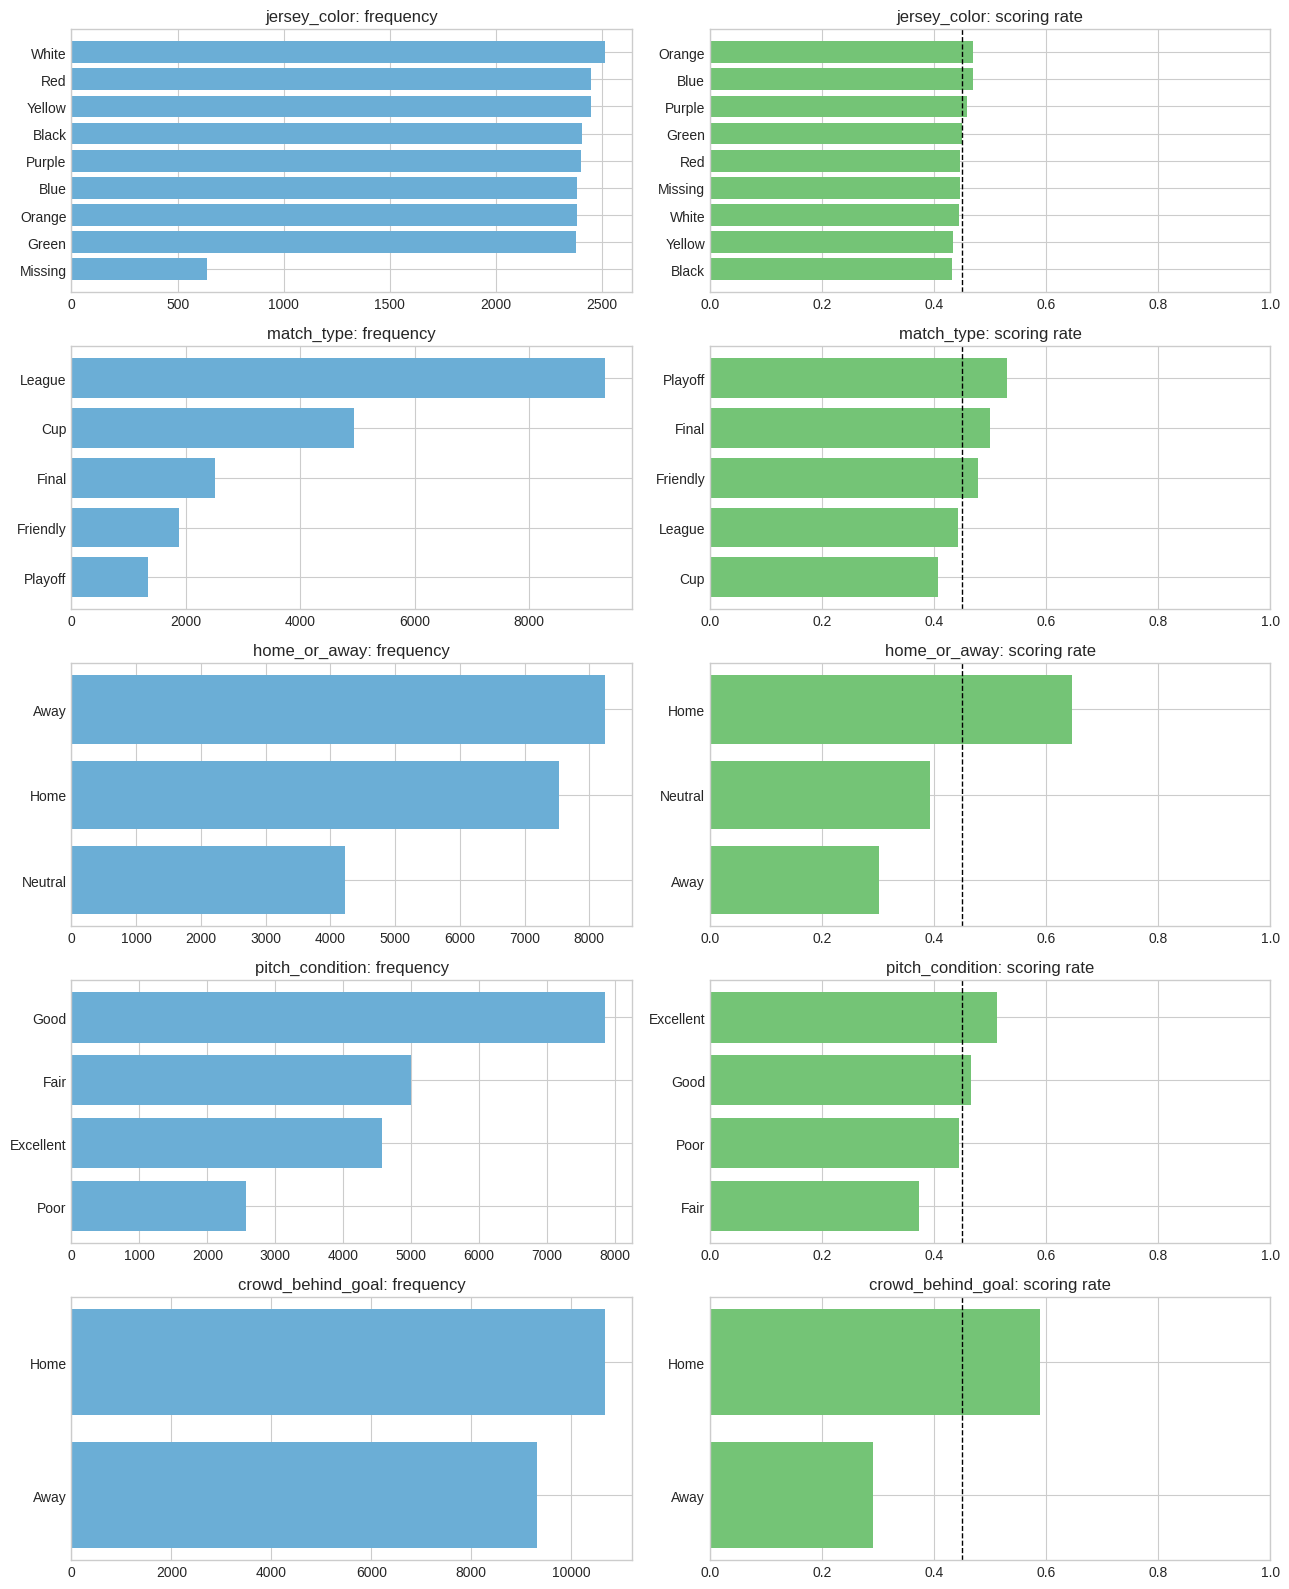

In [7]:
categorical = [c for c in train.select_dtypes(include=["object", "string"]).columns if c not in ID_COLUMNS]
fig, axes = plt.subplots(len(categorical), 2, figsize=(13, 3.2 * len(categorical)))
for row, column in enumerate(categorical):
    values = train[column].fillna("Missing")
    counts = values.value_counts().sort_values()
    rates = train.assign(_category=values).groupby("_category")[TARGET].mean().sort_values()
    axes[row, 0].barh(counts.index.astype(str), counts.values, color="#6baed6")
    axes[row, 0].set_title(f"{column}: frequency")
    axes[row, 1].barh(rates.index.astype(str), rates.values, color="#74c476")
    axes[row, 1].axvline(train[TARGET].mean(), color="black", linestyle="--", linewidth=1)
    axes[row, 1].set(title=f"{column}: scoring rate", xlim=(0, 1))
plt.tight_layout()
plt.show()

In [8]:
id_audit = pd.DataFrame({
    "unique": [train[c].nunique(dropna=False) for c in ID_COLUMNS],
    "unique_%": [train[c].nunique(dropna=False) / len(train) * 100 for c in ID_COLUMNS],
}, index=ID_COLUMNS)
display(id_audit)
print("Near-unique identifiers will be excluded from the first baseline.")

,unique,unique_%
id,20000,100.0000
kicker_id,20000,100.0000
keeper_id,20000,100.0000
match_id,20000,100.0000


Near-unique identifiers will be excluded from the first baseline.


## 5. Numerical distributions and unusual-value candidates

A **distribution** shows where values concentrate and how widely they spread. A **histogram** groups values into ranges. Overlapping missed/scored histograms can suggest useful signal, skew, or interactions.

The **IQR** is the width of the middle 50% of a feature. A simple rule flags values below `Q1 − 1.5 × IQR` or above `Q3 + 1.5 × IQR`. A flagged row is only a candidate to inspect: it may be a valid rare penalty, not an error.

**Next action:** use the small table to choose what to highlight, use PCA for the clear visual check, and compare treatments in Notebook 08. Nothing is deleted here.


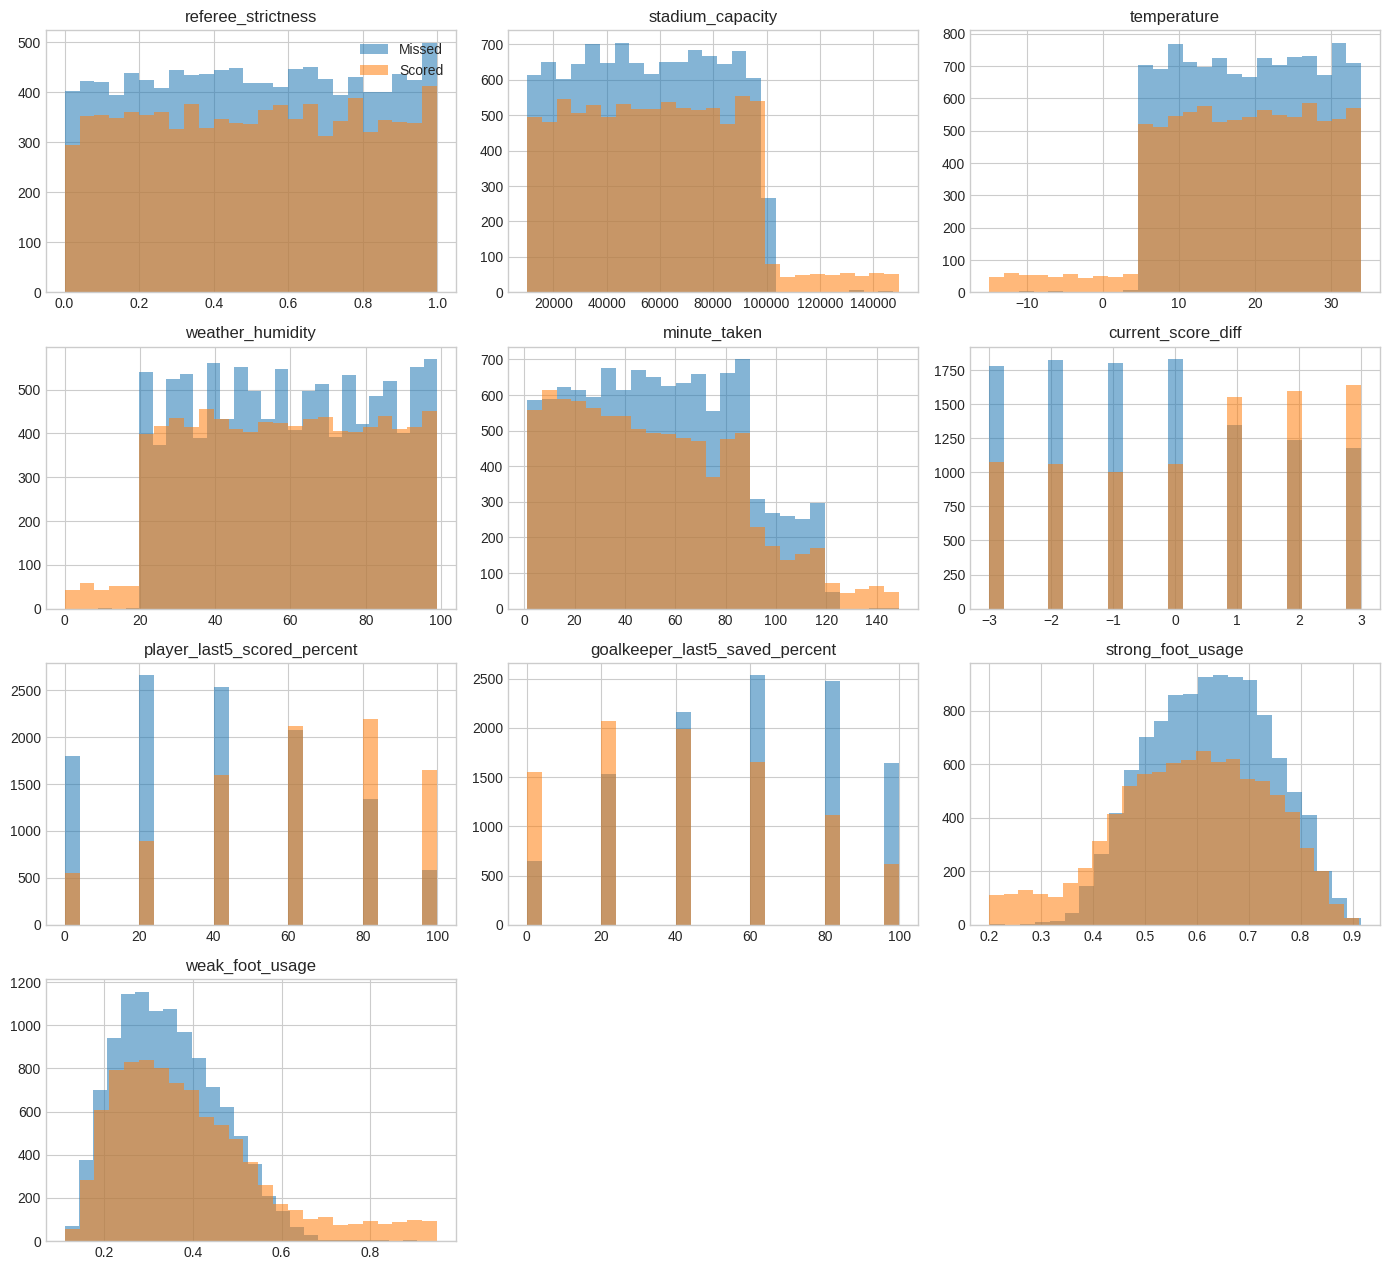

feature,flagged rows,flagged rows (%)
weak_foot_usage,605,3.02%
strong_foot_usage,121,0.60%
temperature,48,0.25%
stadium_capacity,27,0.14%
referee_strictness,0,0.00%
weather_humidity,0,0.00%


Example: weak_foot_usage has 605 rows outside its usual range (3.02%).
The PCA plot below shows whether those rows also look unusual across many numerical features.


In [9]:
numerical = [c for c in train.select_dtypes(include=np.number).columns if c not in set(ID_COLUMNS + [TARGET])]
ncols = 3
nrows = int(np.ceil(len(numerical) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows))
for ax, column in zip(axes.flat, numerical):
    ax.hist(train.loc[train[TARGET] == 0, column].dropna(), bins=25, alpha=.55, label="Missed")
    ax.hist(train.loc[train[TARGET] == 1, column].dropna(), bins=25, alpha=.55, label="Scored")
    ax.set_title(column)
for ax in axes.flat[len(numerical):]:
    ax.remove()
axes.flat[0].legend()
plt.tight_layout()
plt.show()

def iqr_candidate_summary(series):
    values = series.dropna()
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    mask = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    return int(mask.sum()), mask.mean() * 100

outlier_rows = []
for column in numerical:
    flagged_rows, flagged_percent = iqr_candidate_summary(train[column])
    outlier_rows.append({
        "feature": column,
        "flagged rows": flagged_rows,
        "flagged rows (%)": flagged_percent,
    })

outlier_table = pd.DataFrame(outlier_rows).sort_values("flagged rows (%)", ascending=False)
display(outlier_table.head(6).style.hide(axis="index").format({"flagged rows (%)": "{:.2f}%"}))
top_outlier_feature = outlier_table.iloc[0]["feature"]
print(
    f"Example: {top_outlier_feature} has {outlier_table.iloc[0]['flagged rows']} rows "
    f"outside its usual range ({outlier_table.iloc[0]['flagged rows (%)']:.2f}%)."
)
print("The PCA plot below shows whether those rows also look unusual across many numerical features.")


### PCA view of the unusual-value candidates

**PCA** compresses several numerical columns into two summary axes (`PC1` and `PC2`) so we can draw them. Nearby points have broadly similar standardized numerical profiles.

Red crosses are rows flagged by the simple rule for the feature with the most candidates. If they form a visible group, we have a concrete subgroup to investigate. Separation still does not prove that those rows should be removed.


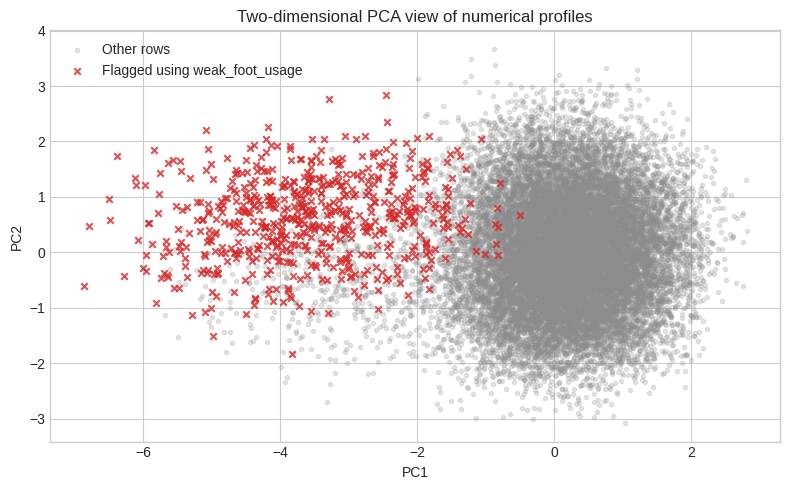

Red rows: 605 of 20,000 (3.02%).
Interpretation: separation makes the subgroup easy to investigate; it does not justify deletion.


In [10]:
pca_frame = train[numerical].copy()
pca_frame = pca_frame.fillna(pca_frame.median())
pca_values = StandardScaler().fit_transform(pca_frame)
pca_coordinates = PCA(n_components=2, random_state=42).fit_transform(pca_values)

candidate_values = train[top_outlier_feature]
q1, q3 = candidate_values.quantile([0.25, 0.75])
iqr = q3 - q1
candidate_mask = (candidate_values < q1 - 1.5 * iqr) | (candidate_values > q3 + 1.5 * iqr)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(pca_coordinates[~candidate_mask, 0], pca_coordinates[~candidate_mask, 1],
           s=9, alpha=0.22, color="#8c8c8c", label="Other rows")
ax.scatter(pca_coordinates[candidate_mask, 0], pca_coordinates[candidate_mask, 1],
           s=22, alpha=0.8, marker="x", color="#d62728",
           label=f"Flagged using {top_outlier_feature}")
ax.set(title="Two-dimensional PCA view of numerical profiles", xlabel="PC1", ylabel="PC2")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Red rows: {candidate_mask.sum():,} of {len(train):,} ({candidate_mask.mean():.2%}).")
print("Interpretation: separation makes the subgroup easy to investigate; it does not justify deletion.")


## 6. Numerical relationships and decoy hypotheses

**Correlation** measures a straight-line relationship from `−1` to `+1`. `absolute_correlation` ignores direction and keeps strength from `0` to `1`.

A value near zero does not prove a feature is useless: the relationship may be curved or depend on another feature. We use these plots to suggest **decoy candidates**, then Notebook 06 tests removal with cross-validation.


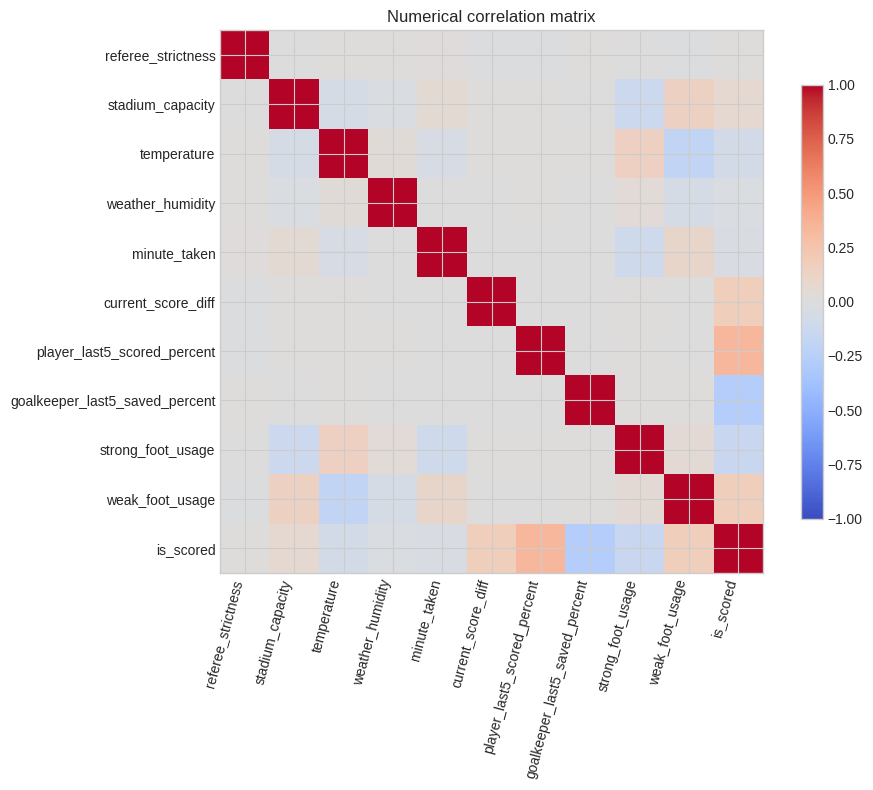

,absolute_correlation
player_last5_scored_percent,0.3347
goalkeeper_last5_saved_percent,0.2657
current_score_diff,0.1699
weak_foot_usage,0.1644
strong_foot_usage,0.1457
temperature,0.0727
stadium_capacity,0.0631
minute_taken,0.0329
weather_humidity,0.0286
referee_strictness,0.0015


Strongest numerical linear relationship: player_last5_scored_percent (0.335).


In [11]:
corr_columns = numerical + [TARGET]
corr = train[corr_columns].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=75, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
fig.colorbar(image, ax=ax, shrink=.8)
ax.set_title("Numerical correlation matrix")
plt.tight_layout()
plt.show()
absolute_target_correlation = corr[TARGET].drop(TARGET).abs().sort_values(ascending=False)
display(absolute_target_correlation.rename("absolute_correlation").to_frame())
print(
    f"Strongest numerical linear relationship: {absolute_target_correlation.index[0]} "
    f"({absolute_target_correlation.iloc[0]:.3f})."
)

### From weak one-feature signal to a decoy hypothesis

- Numerical bars use **absolute correlation** with the target.
- Categorical bars use the gap between the highest and lowest category scoring rate.
- Orange marks the decoy candidates that we will test removing.

These two scores have different meanings and must not be compared directly. A weak bar is only a hypothesis: Notebook 06 uses an **ablation**, meaning it removes the candidate features and checks whether unseen-fold F1 improves.


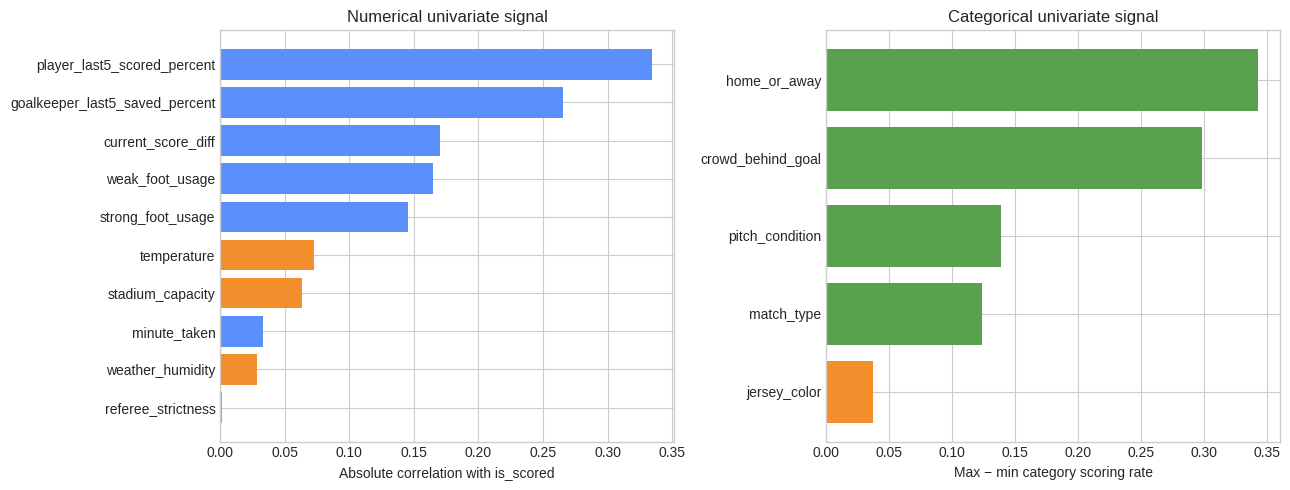

,feature,screening_measure,screening_value
0,jersey_color,category scoring-rate range,0.0371
1,referee_strictness,absolute correlation,0.0015
2,stadium_capacity,absolute correlation,0.0631
3,temperature,absolute correlation,0.0727
4,weather_humidity,absolute correlation,0.0286


Next action: Notebook 06 validates whether removing these candidates preserves or improves F1.


In [12]:
known_decoys = ["jersey_color", "referee_strictness", "stadium_capacity", "temperature", "weather_humidity"]

numeric_association = train[numerical + [TARGET]].corr(numeric_only=True)[TARGET].drop(TARGET).abs().sort_values()
# Compare the highest and lowest scoring rates within each category feature.
category_ranges = {}
for column in categorical:
    scoring_rates = train.groupby(column, dropna=False)[TARGET].mean()
    category_ranges[column] = scoring_rates.max() - scoring_rates.min()
category_rate_range = pd.Series(category_ranges).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(numeric_association.index, numeric_association.values,
             color=["#f28e2b" if name in known_decoys else "#5b8ff9" for name in numeric_association.index])
axes[0].set(title="Numerical univariate signal", xlabel="Absolute correlation with is_scored", ylabel="")
axes[1].barh(category_rate_range.index, category_rate_range.values,
             color=["#f28e2b" if name in known_decoys else "#59a14f" for name in category_rate_range.index])
axes[1].set(title="Categorical univariate signal", xlabel="Max − min category scoring rate", ylabel="")
plt.tight_layout()
plt.show()

decoy_screen = pd.DataFrame({
    "feature": known_decoys,
    "screening_measure": [
        "category scoring-rate range" if column in categorical else "absolute correlation"
        for column in known_decoys
    ],
    "screening_value": [
        category_rate_range.get(column, numeric_association.get(column, np.nan))
        for column in known_decoys
    ],
})
display(decoy_screen)
print("Next action: Notebook 06 validates whether removing these candidates preserves or improves F1.")


## 7. Direct train/test distribution check

**Distribution shift** means a feature has a different pattern in train and test. A model learns rules from train, so a rule built around a train-only pattern may not help on test.

We avoid one abstract “shift score.” Instead, the tables show quantities with direct meanings:

- for numbers: train/test medians and the percentage outside limits learned from train;
- for categories: the percentage of rows in each category in train and test;
- **difference (percentage points):** direct subtraction, such as `3% − 0% = 3 points`.

The plots then show the two largest differences using the original feature values.


feature,train median,test median,train outside usual range (%),test outside usual range (%),difference (percentage points)
weak_foot_usage,0.34,0.34,3.02,0.00,3.02
temperature,19.00,19.00,0.70,0.00,0.70
strong_foot_usage,0.61,0.62,0.60,0.00,0.60
stadium_capacity,56315.00,54995.00,0.24,0.00,0.24
referee_strictness,0.50,0.51,0.00,0.00,0.00
weather_humidity,59.00,59.00,0.00,0.00,0.00
current_score_diff,0.00,0.00,0.00,0.00,0.00
minute_taken,51.00,50.00,0.00,0.00,0.00


feature,category,train rows (%),test rows (%),difference (percentage points)
match_type,League,46.65,50.65,4.00
jersey_color,Missing,3.19,0.00,3.19
pitch_condition,Poor,12.85,10.05,2.79
pitch_condition,Excellent,22.87,25.38,2.51
match_type,Final,12.58,10.08,2.50
crowd_behind_goal,Home,53.41,55.82,2.41
crowd_behind_goal,Away,46.59,44.18,2.41
home_or_away,Home,37.64,39.72,2.08


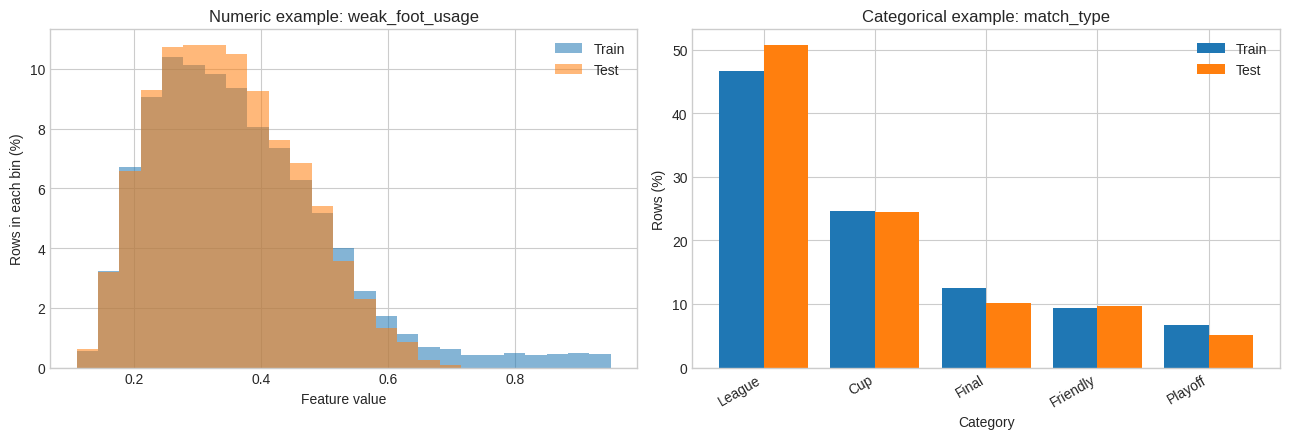

Concrete example: weak_foot_usage has 3.02% flagged rows in train and 0.00% in test.


In [13]:
# Numerical comparison: the IQR limits are learned from train, then reused on test.
numeric_rows = []
for column in numerical:
    train_values = train[column]
    test_values = test[column]
    train_filled = train_values.fillna(train_values.median())
    test_filled = test_values.fillna(train_values.median())
    q1, q3 = train_filled.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    train_rate = ((train_filled < lower) | (train_filled > upper)).mean() * 100
    test_rate = ((test_filled < lower) | (test_filled > upper)).mean() * 100
    numeric_rows.append({
        "feature": column,
        "train median": train_filled.median(),
        "test median": test_filled.median(),
        "train outside usual range (%)": train_rate,
        "test outside usual range (%)": test_rate,
        "difference (percentage points)": abs(train_rate - test_rate),
    })

numeric_comparison = pd.DataFrame(numeric_rows).sort_values(
    "difference (percentage points)", ascending=False
)
display(numeric_comparison.head(8).style.hide(axis="index").format(precision=2))

# Categorical comparison: one row per visible category.
category_rows = []
for column in categorical:
    train_freq = train[column].fillna("Missing").value_counts(normalize=True).mul(100)
    test_freq = test[column].fillna("Missing").value_counts(normalize=True).mul(100)
    for category in train_freq.index.union(test_freq.index):
        train_percent = train_freq.get(category, 0.0)
        test_percent = test_freq.get(category, 0.0)
        category_rows.append({
            "feature": column,
            "category": category,
            "train rows (%)": train_percent,
            "test rows (%)": test_percent,
            "difference (percentage points)": abs(train_percent - test_percent),
        })

categorical_comparison = pd.DataFrame(category_rows).sort_values(
    "difference (percentage points)", ascending=False
)
display(categorical_comparison.head(8).style.hide(axis="index").format(precision=2))

# Clear examples in the original units.
largest_numeric_feature = numeric_comparison.iloc[0]["feature"]
largest_categorical_feature = categorical_comparison.iloc[0]["feature"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
combined_numeric = pd.concat([train[largest_numeric_feature], test[largest_numeric_feature]]).dropna()
bins = np.histogram_bin_edges(combined_numeric, bins=25)
axes[0].hist(
    train[largest_numeric_feature].dropna(), bins=bins,
    weights=np.full(train[largest_numeric_feature].notna().sum(), 100 / train[largest_numeric_feature].notna().sum()),
    alpha=.55, label="Train",
)
axes[0].hist(
    test[largest_numeric_feature].dropna(), bins=bins,
    weights=np.full(test[largest_numeric_feature].notna().sum(), 100 / test[largest_numeric_feature].notna().sum()),
    alpha=.55, label="Test",
)
axes[0].set(title=f"Numeric example: {largest_numeric_feature}", xlabel="Feature value", ylabel="Rows in each bin (%)")
axes[0].legend()

train_category = train[largest_categorical_feature].fillna("Missing").value_counts(normalize=True).mul(100)
test_category = test[largest_categorical_feature].fillna("Missing").value_counts(normalize=True).mul(100)
category_names = train_category.index.union(test_category.index)
x_positions = np.arange(len(category_names))
axes[1].bar(x_positions - .2, train_category.reindex(category_names, fill_value=0), width=.4, label="Train")
axes[1].bar(x_positions + .2, test_category.reindex(category_names, fill_value=0), width=.4, label="Test")
axes[1].set_xticks(x_positions, category_names, rotation=30, ha="right")
axes[1].set(title=f"Categorical example: {largest_categorical_feature}", xlabel="Category", ylabel="Rows (%)")
axes[1].legend()
plt.tight_layout()
plt.show()

largest_numeric = numeric_comparison.iloc[0]
print(
    f"Concrete example: {largest_numeric['feature']} has "
    f"{largest_numeric['train outside usual range (%)']:.2f}% flagged rows in train and "
    f"{largest_numeric['test outside usual range (%)']:.2f}% in test."
)


## 8. ML problem map

This table turns EDA observations into later experiments.

- **Validation:** estimate performance on unseen rows.
- **F1:** balances precision (how many predicted scores were correct) and recall (how many real scores were found).
- **Stratified split:** keeps similar class proportions in each split.
- **Scaling:** puts numerical features on comparable ranges.
- **Encoding:** converts categories into numbers a model can use.

In [14]:
largest_numeric = numeric_comparison.iloc[0]
problem_map = pd.DataFrame([
    ["Duplicates", f"{train.duplicated().sum()} exact duplicate rows", "Inspect before removing; none require action here", "01"],
    ["Unique identifiers", "ID columns are nearly unique", "Exclude from baseline; no repeat history is available", "02"],
    ["Validation + metrics", "F1 is the official metric", "Build OOF predictions and a trusted measuring system", "02"],
    ["Missing values", f"{len(missing)} affected columns; max {missing.max():.2f}%", "Compare imputation, indicators, and explain dropna", "03"],
    ["Feature scales/skew", "Numerical units differ strongly", "Compare scalers and a signed-log candidate", "03"],
    ["Categories", f"{len(categorical)} low-cardinality model categories", "Compare one-hot, ordinal, frequency, target", "04"],
    ["Feature ideas", "Scoring-rate and domain hypotheses", "Create and validate concrete derived features", "05"],
    ["Decoy/weak features", "Low univariate signal is only a clue", "Test ablation and learned selectors", "06"],
    ["Many encoded columns", "Encoding and engineering increase dimensions", "Compare named features with PCA/SVD/LDA", "07"],
    ["Unusual values", f"{outlier_table.iloc[0]['flagged rows']} rows flagged in {top_outlier_feature}", "Use PCA diagnostics; compare clipping/indicators", "08"],
    ["Class balance", f"Largest class {largest_class:.1f}%", "Compare none, weights, over/under-sampling, synthetic methods", "09"],
    [
        "Train/test difference",
        f"{largest_numeric['feature']}: {largest_numeric['train outside usual range (%)']:.2f}% train vs {largest_numeric['test outside usual range (%)']:.2f}% test",
        "Check whether validation gains depend on a train-only subgroup",
        "01/08",
    ],
], columns=["Finding", "Evidence", "What we do next", "Notebook"])
display(problem_map.style.hide(axis="index"))


Finding,Evidence,What we do next,Notebook
Duplicates,0 exact duplicate rows,Inspect before removing; none require action here,01
Unique identifiers,ID columns are nearly unique,Exclude from baseline; no repeat history is available,02
Validation + metrics,F1 is the official metric,Build OOF predictions and a trusted measuring system,02
Missing values,6 affected columns; max 3.19%,"Compare imputation, indicators, and explain dropna",03
Feature scales/skew,Numerical units differ strongly,Compare scalers and a signed-log candidate,03
Categories,5 low-cardinality model categories,"Compare one-hot, ordinal, frequency, target",04
Feature ideas,Scoring-rate and domain hypotheses,Create and validate concrete derived features,05
Decoy/weak features,Low univariate signal is only a clue,Test ablation and learned selectors,06
Many encoded columns,Encoding and engineering increase dimensions,Compare named features with PCA/SVD/LDA,07
Unusual values,605 rows flagged in weak_foot_usage,Use PCA diagnostics; compare clipping/indicators,08


## Why these EDA decisions are justified

**Technical evidence:** there are no exact duplicate rows, IDs are nearly unique, missingness is low, the target split is mild, and visible outlier/shift candidates require controlled tests.

**Theoretical reason:** EDA generates hypotheses; it cannot estimate how a treatment performs on unseen rows. Therefore we keep the raw data intact and route each finding to a leakage-safe validation experiment in Notebooks 02–09.
